<a href="https://colab.research.google.com/github/kaluarachchiteshan/agromaster-risk-calculation-ml/blob/08-final-test-evaluation/notebooks/08_final_test_evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# 08 - Final evaluation on the untouched test period (proposal 4.6 and 4.8) | Group 41 AgroMaster
# Model selection is already finished: XGBoost on the extended features had the best mean validation macro F1.
# Every model is fitted once on the development period with its tuned settings and scored once on the test period.
from google.colab import drive
drive.mount('/content/drive')

import os, json, time, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

OUT_DIR = "/content/drive/MyDrive/agromaster"
FIG_DIR = os.path.join(OUT_DIR, "figures"); os.makedirs(FIG_DIR, exist_ok=True)

# ---------------- CONFIG ----------------
SELECTED = "XGBoost"       # chosen on validation macro F1 in notebook 07, before looking at the test period
MAX_TRAIN_ROWS = None      # None = fit on all development rows; set e.g. 2_000_000 if the session runs out of memory
SEED = 42
# ----------------------------------------
cfg  = json.load(open(os.path.join(OUT_DIR, "feature_config.json")))
spl  = json.load(open(os.path.join(OUT_DIR, "splits.json")))
best = json.load(open(os.path.join(OUT_DIR, "best_params_extended.json")))
EXTRA = json.load(open(os.path.join(OUT_DIR, "extended_features.json")))["extra_features"]
NUM, CAT = cfg["num_features"] + EXTRA, cfg["cat_features"]
N_BLOCKS, Q_HIGH, Q_MEDIUM, CLASS_NAMES = spl["n_blocks"], spl["q_high"], spl["q_medium"], spl["class_names"]

data = pd.read_parquet(os.path.join(OUT_DIR, "model_table.parquet"))
data = data[data["block"] >= 0].copy()
data["rel_mean_90"] = data["current_ratio"]                        # same 7 relative features as notebook 07
data["rel_ma_30"]   = data["modal_price"] / data["ma_30"]
data["rel_ma_7"]    = data["modal_price"] / data["ma_7"]
data["trend_30_90"] = data["ma_30"] / data["hist_mean_90"]
data["cv_30"]       = data["volatility_30"] / data["ma_30"]
data["change_1"]    = data["modal_price"] / data["modal_lag_1"] - 1
data["change_30"]   = data["modal_price"] / data["modal_lag_30"] - 1

def make_labels(d, thr, col="ratio"):
    """0 = Low, 1 = Medium, 2 = High risk, using the thresholds of each row's commodity."""
    p_high = d["commodity"].astype(str).map(thr["p_high"]).to_numpy(dtype="float64")
    p_med  = d["commodity"].astype(str).map(thr["p_medium"]).to_numpy(dtype="float64")
    r = d[col].to_numpy(dtype="float64")
    return np.where(r <= p_high, 2, np.where(r <= p_med, 1, 0)).astype("int8")

dev, test = data[data["block"] < N_BLOCKS], data[data["block"] == N_BLOCKS]
del data
thr = dev.groupby("commodity", observed=True)["ratio"].quantile([Q_HIGH, Q_MEDIUM]).unstack()   # thresholds from development only
thr.columns = ["p_high", "p_medium"]
thr.to_csv(os.path.join(OUT_DIR, "final_thresholds.csv"))
y_test = make_labels(test, thr)
if MAX_TRAIN_ROWS and len(dev) > MAX_TRAIN_ROWS:
    dev = dev.sample(MAX_TRAIN_ROWS, random_state=SEED)
y_dev = make_labels(dev, thr)

print(f"Development: {len(dev):,} rows ({dev['date'].min().date()} to {dev['date'].max().date()})")
print(f"Test:        {len(test):,} rows ({test['date'].min().date()} to {test['date'].max().date()})")
print("Final thresholds (ratio at or below p_high = High risk):\n" + thr.round(3).to_string())
print("Class share Low/Medium/High - development:", np.round(np.bincount(y_dev, minlength=3) / len(y_dev), 3),
      "| test:", np.round(np.bincount(y_test, minlength=3) / len(y_test), 3))

Mounted at /content/drive
Development: 5,164,715 rows (2001-08-04 to 2023-12-24)
Test:        613,070 rows (2024-01-01 to 2025-10-30)
Final thresholds (ratio at or below p_high = High risk):
              p_high  p_medium
commodity                     
Brinjal        0.596     0.821
Green Chilli   0.598     0.824
Onion          0.619     0.855
Potato         0.657     0.908
Tomato         0.478     0.724
Class share Low/Medium/High - development: [0.7 0.2 0.1] | test: [0.715 0.202 0.082]


In [ ]:
# Fit every model once on the development period and predict the test period
preds = {"Majority class": np.full(len(test), np.bincount(y_dev).argmax(), dtype="int8"),
         "Risk persistence": make_labels(test, thr, col="current_ratio")}
results_file = os.path.join(OUT_DIR, "test_predictions.parquet")

def fit_predict(name, model, X_dev, X_test, **fit_kwargs):
    """Fit on development, predict test, keep the predictions and report the time taken."""
    t0 = time.time()
    model.fit(X_dev, y_dev, **fit_kwargs)
    preds[name] = model.predict(X_test).astype("int8")
    print(f"{name:22s} fitted in {time.time() - t0:5.0f}s | settings: {best[name]}")
    return model

# --- linear-style inputs: median imputation + standardisation + one-hot (fitted on development only) ---
lin_prep = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), NUM),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False, dtype="float32"), CAT)])
X_dev, X_test = lin_prep.fit_transform(dev).astype("float32"), lin_prep.transform(test).astype("float32")
fit_predict("Gaussian Naive Bayes", GaussianNB(priors=[1/3, 1/3, 1/3], **best["Gaussian Naive Bayes"]), X_dev, X_test)
fit_predict("Logistic Regression", LogisticRegression(class_weight="balanced", max_iter=300, **best["Logistic Regression"]), X_dev, X_test)
del X_dev, X_test

# --- tree-style inputs: median imputation + ordinal-encoded categories (fitted on development only) ---
tree_prep = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), NUM),
    ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), CAT)])
X_dev, X_test = tree_prep.fit_transform(dev).astype("float32"), tree_prep.transform(test).astype("float32")
fit_predict("Decision Tree", DecisionTreeClassifier(class_weight="balanced", random_state=SEED, **best["Decision Tree"]), X_dev, X_test)
fit_predict("Random Forest", RandomForestClassifier(n_estimators=100, class_weight="balanced_subsample", max_samples=100_000,
                                                    n_jobs=-1, random_state=SEED, **best["Random Forest"]), X_dev, X_test)

# XGBoost: no early stopping here (that would need the test period). The number of trees comes from the validation folds.
cv = pd.read_csv(os.path.join(OUT_DIR, "cv_results_models_extended.csv"))
cv = cv[(cv["model"] == "XGBoost") & (cv["params"] == json.dumps(best["XGBoost"], sort_keys=True))]
n_trees = int(cv["best_iteration"].mean() * 1.1) + 1
print(f"XGBoost trees: {n_trees} (mean best iteration over the folds = {cv['best_iteration'].mean():.0f})")
xgb = fit_predict("XGBoost", XGBClassifier(n_estimators=n_trees, tree_method="hist", objective="multi:softprob", n_jobs=-1,
                                           random_state=SEED, **best["XGBoost"]),
                  X_dev, X_test, sample_weight=compute_sample_weight("balanced", y_dev))

# Save everything the interpretation notebook needs
out = test[["sid", "date", "commodity", "state", "market", "ratio", "current_ratio"]].copy()
out["y_true"] = y_test
for name, p in preds.items(): out["pred_" + name] = p
proba = xgb.predict_proba(X_test)
for i, c in enumerate(CLASS_NAMES): out[f"xgb_proba_{c}"] = proba[:, i].astype("float32")
out.to_parquet(results_file, compression="zstd", index=False)
xgb.save_model(os.path.join(OUT_DIR, "final_xgboost.json"))
joblib.dump(tree_prep, os.path.join(OUT_DIR, "final_tree_prep.joblib"))
np.save(os.path.join(OUT_DIR, "final_X_test_tree.npy"), X_test)
print("\nSaved test_predictions.parquet, final_xgboost.json, final_tree_prep.joblib, final_X_test_tree.npy")

Gaussian Naive Bayes   fitted in     5s | settings: {'var_smoothing': 0.001}
Logistic Regression    fitted in   423s | settings: {'C': 0.1}
Decision Tree          fitted in   206s | settings: {'max_depth': 10, 'min_samples_leaf': 500}
Random Forest          fitted in   185s | settings: {'max_depth': 10, 'max_features': 0.5, 'min_samples_leaf': 100}
XGBoost trees: 341 (mean best iteration over the folds = 309)
XGBoost                fitted in   655s | settings: {'colsample_bytree': 1.0, 'learning_rate': 0.1, 'max_depth': 4, 'reg_lambda': 5.0, 'subsample': 0.7}

Saved test_predictions.parquet, final_xgboost.json, final_tree_prep.joblib, final_X_test_tree.npy


FINAL TEST PERIOD - all models:
                      accuracy  macro_precision  macro_recall  macro_f1  high_precision  high_recall  high_f1
Risk persistence         0.844            0.759         0.723     0.739           0.726        0.595    0.654
XGBoost                  0.803            0.699         0.759     0.722           0.618        0.728    0.668
Random Forest            0.798            0.691         0.749     0.713           0.610        0.718    0.660
Decision Tree            0.794            0.677         0.745     0.704           0.573        0.738    0.645
Logistic Regression      0.770            0.653         0.743     0.684           0.537        0.785    0.638
Gaussian Naive Bayes     0.657            0.556         0.623     0.570           0.430        0.618    0.507
Majority class           0.715            0.238         0.333     0.278           0.000        0.000    0.000

Test vs mean validation score (a large drop would mean the model does not generalise to

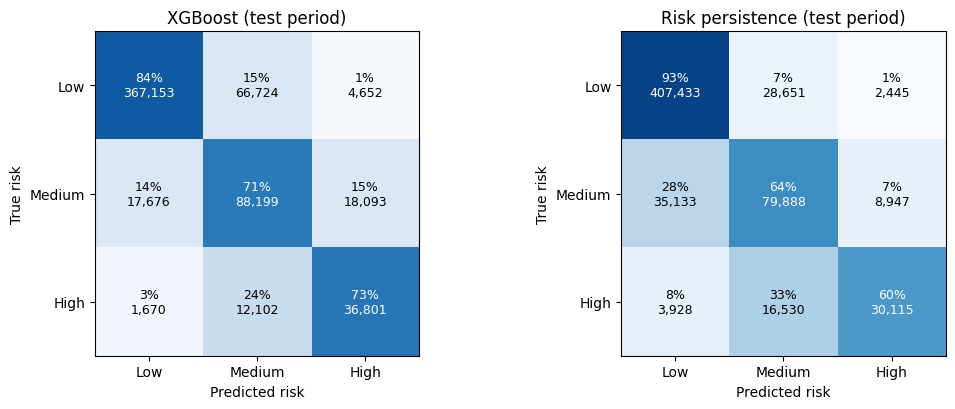

In [ ]:
# Test-period results: all models and baselines
def metrics(y_true, y_pred):
    """All measures listed in the proposal (section 4.8)."""
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, labels=[0, 1, 2], zero_division=0)
    return {"accuracy": accuracy_score(y_true, y_pred), "macro_precision": p.mean(), "macro_recall": r.mean(), "macro_f1": f.mean(),
            "high_precision": p[2], "high_recall": r[2], "high_f1": f[2]}

table = pd.DataFrame({name: metrics(y_test, p) for name, p in preds.items()}).T.sort_values("macro_f1", ascending=False)
table.to_csv(os.path.join(OUT_DIR, "test_results.csv"))
print("FINAL TEST PERIOD - all models:\n" + table.round(3).to_string())

val = pd.read_csv(os.path.join(OUT_DIR, "cv_summary_extended.csv")).set_index("model")
cmp = table[["macro_f1", "high_recall"]].join(val[["macro_f1", "high_recall"]], rsuffix="_validation")
print("\nTest vs mean validation score (a large drop would mean the model does not generalise to newer data):\n" + cmp.round(3).to_string())

print(f"\nSelected model ({SELECTED}) - per-class report:")
print(classification_report(y_test, preds[SELECTED], labels=[0, 1, 2], target_names=CLASS_NAMES, digits=3, zero_division=0))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, name in zip(axes, [SELECTED, "Risk persistence"]):
    cm = confusion_matrix(y_test, preds[name], labels=[0, 1, 2])
    pct = cm / cm.sum(axis=1, keepdims=True)                     # each row sums to 1: share of each true class
    ax.imshow(pct, cmap="Blues", vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{pct[i, j]:.0%}\n{cm[i, j]:,}", ha="center", va="center", color="white" if pct[i, j] > 0.5 else "black", fontsize=9)
    ax.set_xticks(range(3)); ax.set_xticklabels(CLASS_NAMES); ax.set_yticks(range(3)); ax.set_yticklabels(CLASS_NAMES)
    ax.set_xlabel("Predicted risk"); ax.set_ylabel("True risk"); ax.set_title(f"{name} (test period)")
    print(f"Confusion matrix, {name} (rows = true, columns = predicted):\n{pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES).to_string()}\n")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "08_confusion_matrices.png"), dpi=150); plt.show()

In [ ]:
# Results by commodity and by time period (selected model vs the persistence baseline)
def by_group(keys, label):
    rows = []
    for g in pd.unique(keys):
        m = (keys == g)
        row = {label: g, "rows": int(m.sum()), "high_share": float((y_test[m] == 2).mean())}
        for name in [SELECTED, "Risk persistence"]:
            s = metrics(y_test[m], preds[name][m])
            row[f"{name} macro_f1"], row[f"{name} high_recall"] = s["macro_f1"], s["high_recall"]
        rows.append(row)
    return pd.DataFrame(rows).sort_values(label).set_index(label)

com = by_group(test["commodity"].astype(str).to_numpy(), "commodity")
half = (test["date"].dt.year.astype(str) + np.where(test["date"].dt.month <= 6, " H1", " H2")).to_numpy()
per = by_group(half, "period")
com.to_csv(os.path.join(OUT_DIR, "test_results_by_commodity.csv")); per.to_csv(os.path.join(OUT_DIR, "test_results_by_period.csv"))
print("By commodity:\n" + com.round(3).to_string())
print("\nBy half-year:\n" + per.round(3).to_string())

By commodity:
                rows  high_share  XGBoost macro_f1  XGBoost high_recall  Risk persistence macro_f1  Risk persistence high_recall
commodity                                                                                                                       
Brinjal       110156       0.079             0.650                0.667                      0.670                         0.571
Green Chilli   99514       0.074             0.685                0.703                      0.700                         0.562
Onion         153051       0.097             0.748                0.714                      0.759                         0.549
Potato        136636       0.072             0.795                0.812                      0.796                         0.690
Tomato        113713       0.087             0.698                0.736                      0.731                         0.618

By half-year:
           rows  high_share  XGBoost macro_f1  XGBoost high_recall  